# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the SAT 6 dataset.

In [ ]:
from aitlas.datasets import SAT6Dataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [5]:
dataset_config = {
    "mat_file": "/home/dragik/data/SAT6/sat-6-full.mat", 
    "mode": "train"
    }
dataset = SAT6Dataset(dataset_config)

## Show images from the dataset

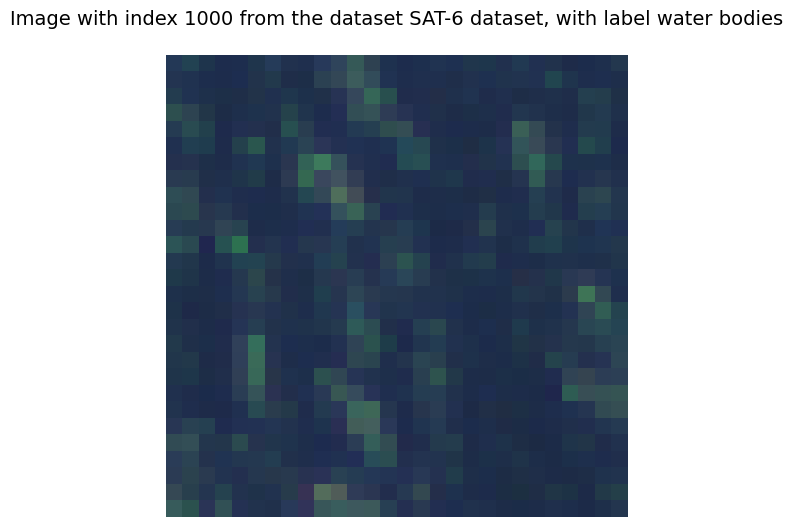

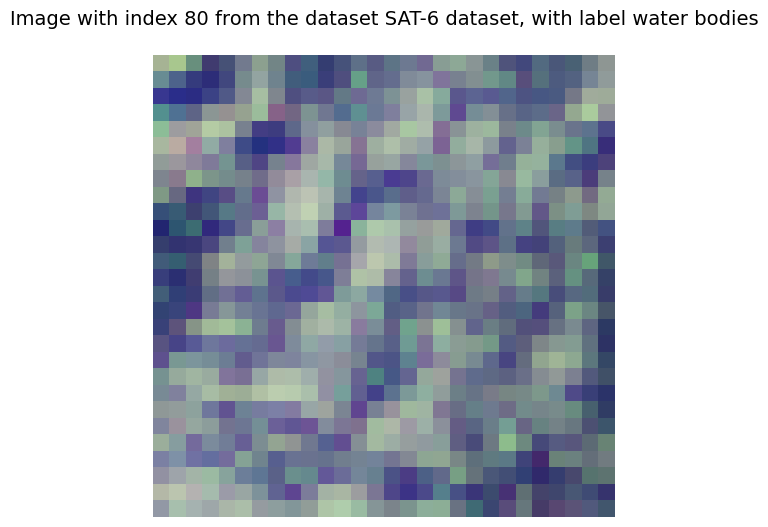

In [6]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

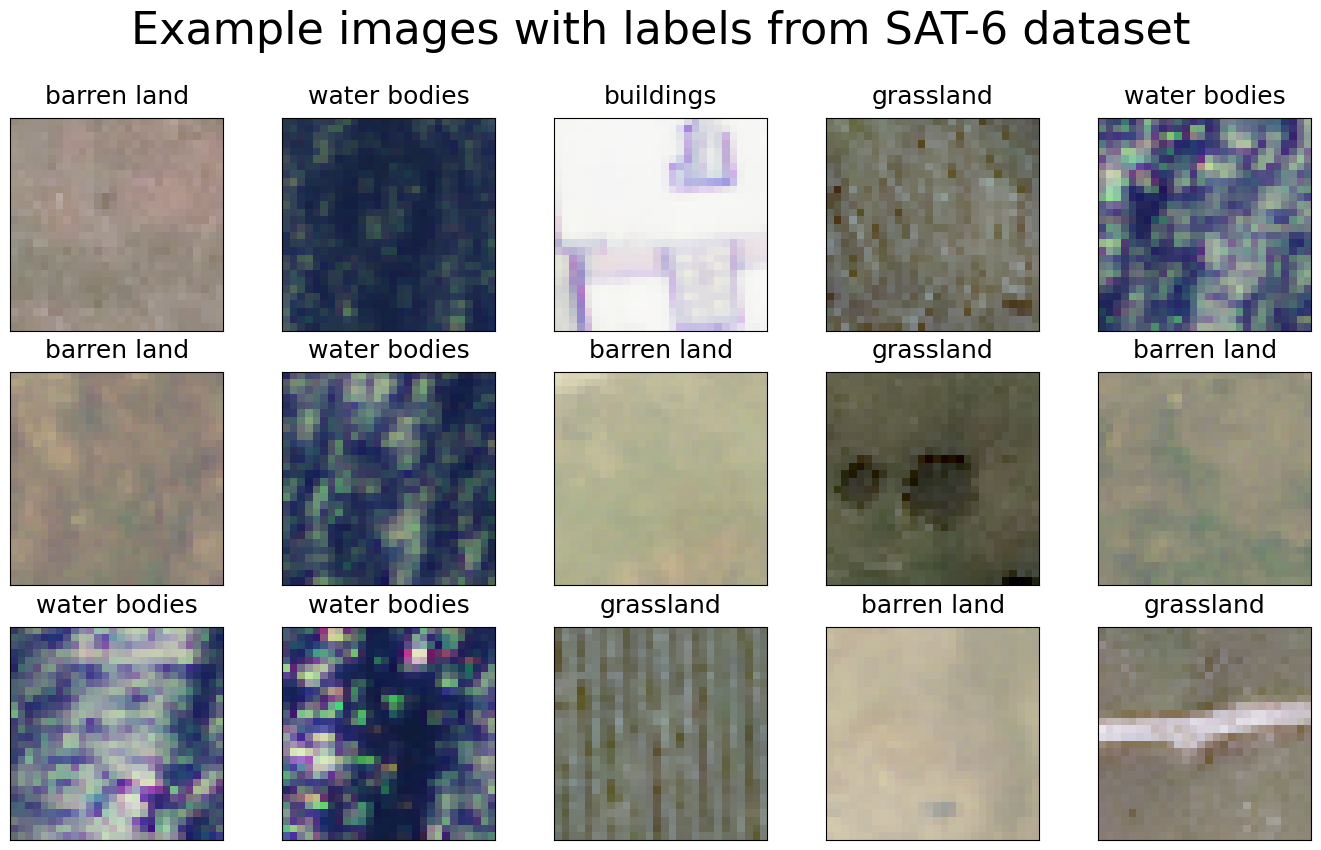

In [7]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [9]:
dataset.data_distribution_table()

,Label,Count
0,barren land,73397
1,buildings,14923
2,grassland,50347
3,roads,8192
4,trees,56809
5,water bodies,120332


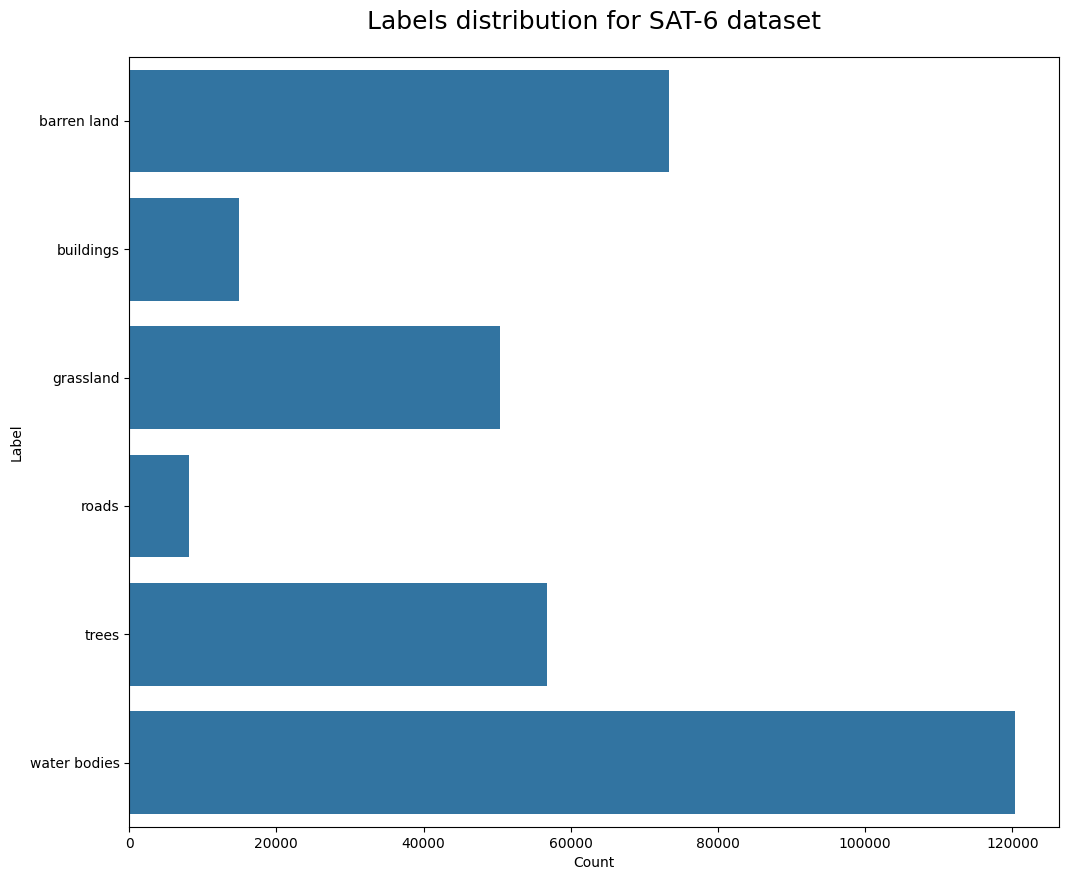

In [10]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [14]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/SAT6/sat-6-full.mat",
    "mode": "train",
}

train_dataset = SAT6Dataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/SAT6/sat-6-full.mat",
    "mode": "test",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = SAT6Dataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(324000, 81000)

## Setup and create the model for training

In [15]:
epochs = 5
model_directory = "/home/dragik/data/experiments/SAT6"
model_config = {
    "num_classes": 6,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [16]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 12:00:51,518 INFO Starting training.
training: 100%|██████████| 20250/20250 [25:30<00:00, 13.23it/s]
2026-08-24 12:26:22,610 INFO epoch: 1, time: 1531, loss:  0.04918
testing on train set: 100%|██████████| 20250/20250 [08:33<00:00, 39.42it/s]
2026-08-24 12:34:57,157 INFO Accuracy:0.9941975308641975, Precision Micro:0.9941975308641975, Precision Macro:0.9929337182354635, Precision Weighted:0.994228738325903, Precision per Class:[0.98635762 0.98410412 0.99806041 0.99297296 0.99614044 0.99996676], Recall Micro:0.9941975308641975, Recall Macro:0.9906657514788639, Recall Weighted:0.9941975308641975, Recall per Class:[0.99805669 0.99615788 0.99637381 0.97672155 0.97668457 1.        ], F1_score Micro:0.9941975308641969, F1_score Macro:0.9917605908984345, F1_score Weighted:0.9941902670290231, F1_score per Class:[0.99217267 0.99009432 0.9972164  0.98478021 0.98631657 0.99998338]
testing on validation set: 100%|██████████| 20250/20250 [02:45<00:00, 122.10it/s]
2026-08-24 12:37:43,007 

0.008590108691262718

## Predictions

2026-08-24 13:46:17,321 INFO Loading checkpoint /home/dragik/data/experiments/SAT6/checkpoint.pth.tar
2026-08-24 13:46:17,522 INFO Loaded checkpoint /home/dragik/data/experiments/SAT6/checkpoint.pth.tar at epoch 6


81000


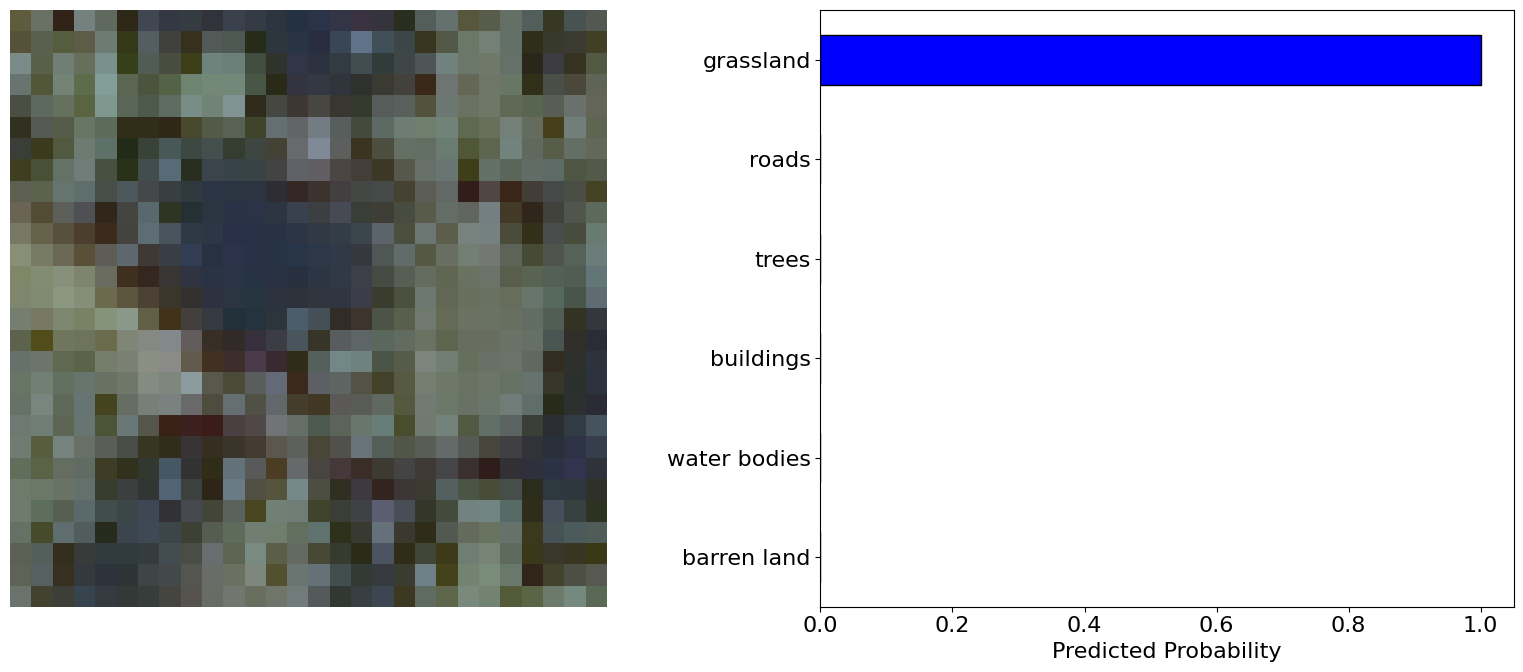

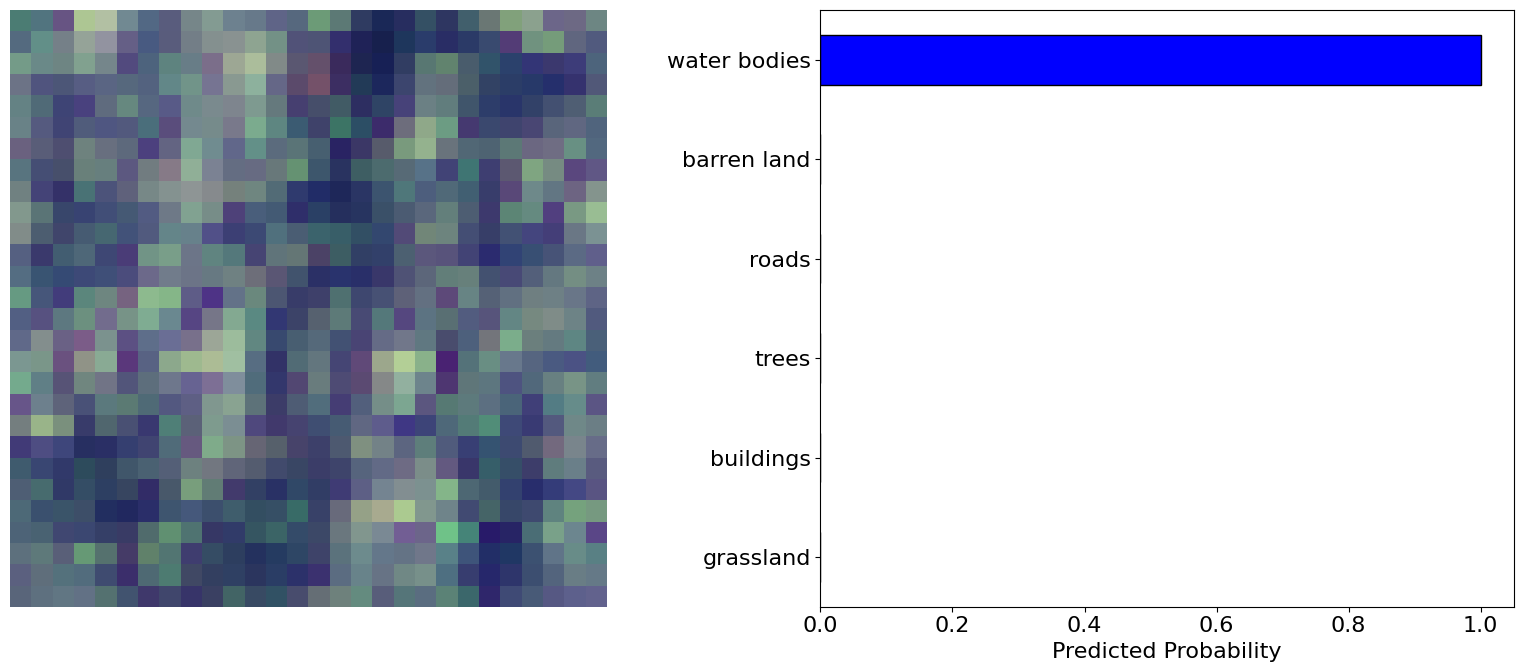

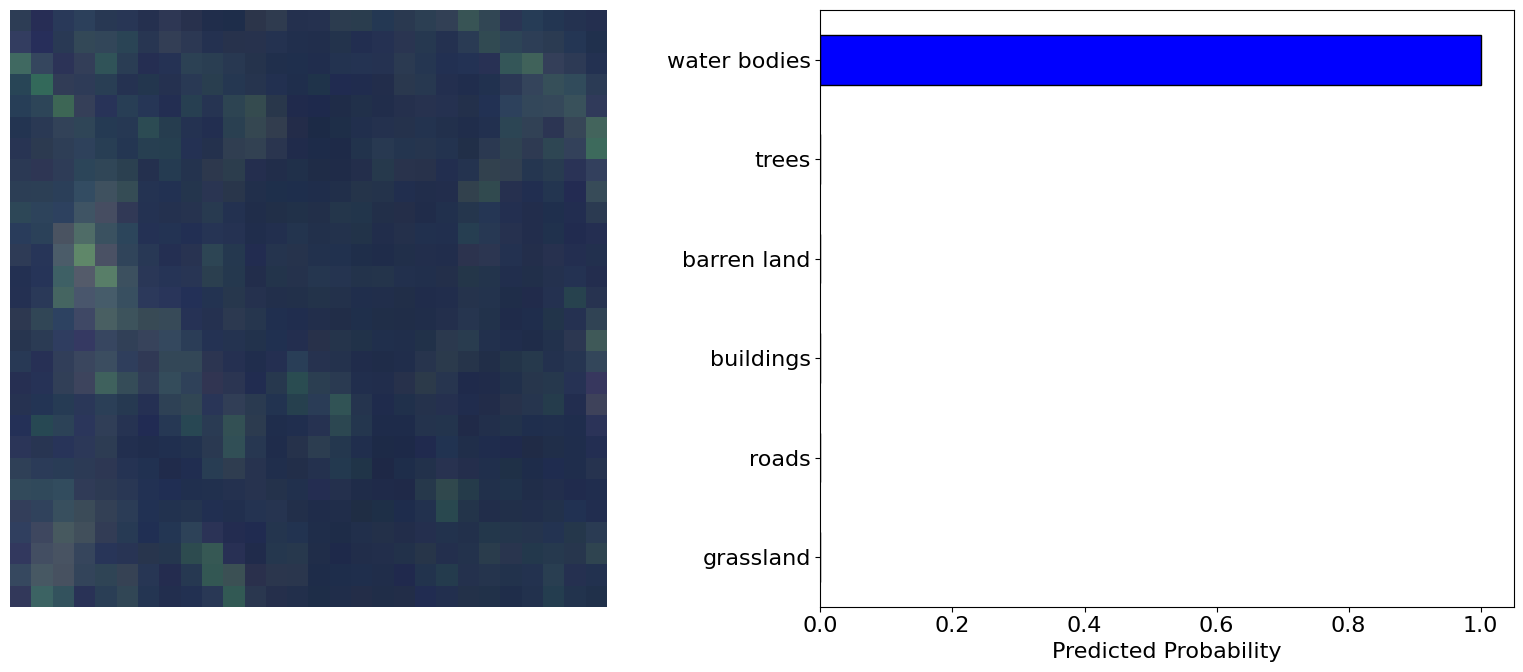

In [17]:
model_path = "/home/dragik/data/experiments/SAT6/checkpoint.pth.tar"
labels = ["barren land", "trees", "grassland", "roads", "buildings", "water bodies"]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "mat_file": "/home/dragik/data/SAT6/sat-6-full.mat",
    "mode": "test"
}

test_dataset = SAT6Dataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)